<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/jobsheet%20dataset%20AntiBurnOut/JS01/01_Data_Exploration_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS01: Exploratory Data Analysis (EDA) - Dataset AntiBurnOut

**Identitas Mahasiswa:**
- **Nama**  : MUHAMMAD ANKA REZA
- **NIM**   : 254107023002
- **Kelas** : TI/3H
- **Dataset**: `mental_health_burnout_prediction_dataset.csv`

---

### Deskripsi Praktikum:
Praktikum ini bertujuan untuk melakukan eksplorasi data awal (*Exploratory Data Analysis*) pada dataset kesehatan mental dan risiko burnout (50.000 responden, 40 atribut fitur). Tahapan yang dilakukan meliputi inspeksi struktur data, statistik deskriptif, pengecekan nilai yang hilang (*missing values*), serta visualisasi distribusi variabel target regresi (`Burnout_Score`) dan klasifikasi (`Burnout_Risk`).

### Langkah 1: Import Library dan Memuat Dataset

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 50)

# Pencarian lokasi dataset secara fleksibel
dataset_candidates = [
    'mental_health_burnout_prediction_dataset.csv',
    '../mental_health_burnout_prediction_dataset.csv',
    'jobsheet dataset AntiBurnOut/mental_health_burnout_prediction_dataset.csv',
    'machine_learning_254107023002/jobsheet dataset AntiBurnOut/mental_health_burnout_prediction_dataset.csv'
]

dataset_path = next((p for p in dataset_candidates if os.path.exists(p)), 'mental_health_burnout_prediction_dataset.csv')
df = pd.read_csv(dataset_path)

print(f"Dataset berhasil dimuat dari: {dataset_path}")
print(f"Dimensi data: {df.shape[0]:,} baris dan {df.shape[1]} kolom")
df.head()

Dataset berhasil dimuat dari: ../mental_health_burnout_prediction_dataset.csv
Dimensi data: 50,000 baris dan 40 kolom


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Sleep_Quality,Stress_Level,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,Physical_Activity_Hours,Exercise_Frequency,Meditation_Minutes,Screen_Time_Hours,Social_Media_Hours,Gaming_Hours,Coffee_Cups_Per_Day,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.0,67,Hybrid,3.0,7.0,4.6,Poor,High,74.0,75.0,26.0,18,8.9,Weekly,5.0,9.1,0.3,0.6,3,Yes,Yes,No,Yes,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.0,44,Hybrid,5.0,8.0,4.7,Poor,Moderate,58.0,80.0,29.0,37,0.8,Weekly,18.0,12.0,4.9,5.2,3,Yes,Yes,Yes,No,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.0,60,No,8.0,7.0,6.3,Average,Moderate,54.0,55.0,44.0,48,6.9,Daily,NaN,10.2,6.7,4.7,3,Yes,No,No,No,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.0,25,Yes,2.0,9.0,7.1,Good,Low,12.0,11.0,88.0,80,7.6,Weekly,55.0,3.3,5.0,4.8,6,Yes,No,No,No,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,NaN,52,No,1.0,4.0,9.1,Excellent,Low,25.0,48.0,67.0,76,6.1,Never,9.0,6.5,1.3,5.7,8,Yes,No,No,No,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


### Langkah 2: Inspeksi Struktur Kolom dan Tipe Data

In [3]:
# Ringkasan informasi dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Person_ID                      50000 non-null  int64  
 1   Age                            49750 non-null  float64
 2   Gender                         50000 non-null  str    
 3   Country                        50000 non-null  str    
 4   Occupation                     50000 non-null  str    
 5   Education_Level                50000 non-null  str    
 6   Employment_Status              50000 non-null  str    
 7   Monthly_Income_USD             48550 non-null  float64
 8   Work_Hours_Per_Week            50000 non-null  int64  
 9   Remote_Work                    50000 non-null  str    
 10  Job_Satisfaction               49500 non-null  float64
 11  Work_Life_Balance              49350 non-null  float64
 12  Sleep_Hours                    49050 non-null  float64
 1

### Langkah 3: Statistik Deskriptif Fitur Numerik dan Kategorik

In [4]:
# Statistik deskriptif untuk fitur numerik utama
num_cols = ['Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Sleep_Hours', 
            'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Burnout_Score']
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,49750.0,41.448181,13.871634,18.0,29.0,41.0,53.0,65.0
Monthly_Income_USD,48550.0,6251.281524,3319.661435,500.0,3381.0,6231.0,9134.0,12000.0
Work_Hours_Per_Week,50000.0,44.946160,14.729024,20.0,32.0,45.0,58.0,70.0
Sleep_Hours,49050.0,6.997445,1.728766,4.0,5.5,7.0,8.5,10.0
Anxiety_Score,49200.0,40.449045,26.004291,0.0,19.0,39.0,59.0,100.0
Depression_Score,49150.0,40.601160,26.308933,0.0,19.0,39.0,60.0,100.0
Mood_Score,49100.0,59.622994,25.783486,0.0,41.0,61.0,80.0,100.0
Burnout_Score,50000.0,40.201880,26.223120,0.0,19.0,39.0,59.0,100.0


In [5]:
# Statistik untuk fitur kategorik target
for col in ['Burnout_Risk', 'Mental_Health_Status', 'Stress_Level']:
    print(f"--- Distribusi {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- Distribusi Burnout_Risk ---
Burnout_Risk
Low         25369
Moderate    14780
High         9851
Name: count, dtype: int64

--- Distribusi Mental_Health_Status ---
Mental_Health_Status
Healthy            25369
Needs Attention    14096
Critical           10535
Name: count, dtype: int64

--- Distribusi Stress_Level ---
Stress_Level
Low         21587
Moderate    21264
High         7149
Name: count, dtype: int64



### Langkah 4: Identifikasi Nilai Hilang (Missing Values)

In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing, 'Percentage': missing_pct})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print(f"Terdapat {len(missing_df)} fitur yang memiliki missing values:")
missing_df

Terdapat 16 fitur yang memiliki missing values:


,Missing_Count,Percentage
Monthly_Income_USD,1450,2.9
Meditation_Minutes,1200,2.4
Physical_Activity_Hours,1100,2.2
Sleep_Hours,950,1.9
Productivity_Score,950,1.9
Mood_Score,900,1.8
Screen_Time_Hours,850,1.7
Depression_Score,850,1.7
Anxiety_Score,800,1.6
Gaming_Hours,750,1.5


### Langkah 5: Visualisasi Distribusi Target dan Korelasi

C:\Users\Pongo\AppData\Local\Temp\ipykernel_21352\2582163960.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Burnout_Risk', order=order, palette=palette)


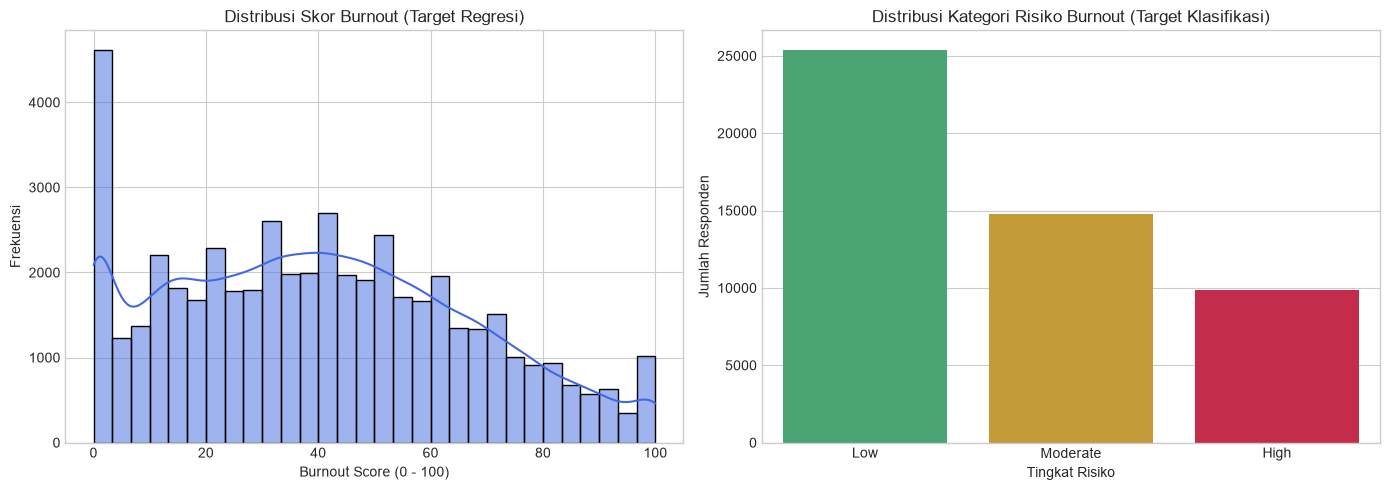

In [7]:
plt.figure(figsize=(14, 5))

# 1. Distribusi Burnout_Score (Target Regresi)
plt.subplot(1, 2, 1)
sns.histplot(df['Burnout_Score'], kde=True, bins=30, color='royalblue')
plt.title('Distribusi Skor Burnout (Target Regresi)', fontsize=12)
plt.xlabel('Burnout Score (0 - 100)')
plt.ylabel('Frekuensi')

# 2. Distribusi Burnout_Risk (Target Klasifikasi)
plt.subplot(1, 2, 2)
order = ['Low', 'Moderate', 'High']
palette = {'Low': 'mediumseagreen', 'Moderate': 'goldenrod', 'High': 'crimson'}
sns.countplot(data=df, x='Burnout_Risk', order=order, palette=palette)
plt.title('Distribusi Kategori Risiko Burnout (Target Klasifikasi)', fontsize=12)
plt.xlabel('Tingkat Risiko')
plt.ylabel('Jumlah Responden')

plt.tight_layout()
plt.show()

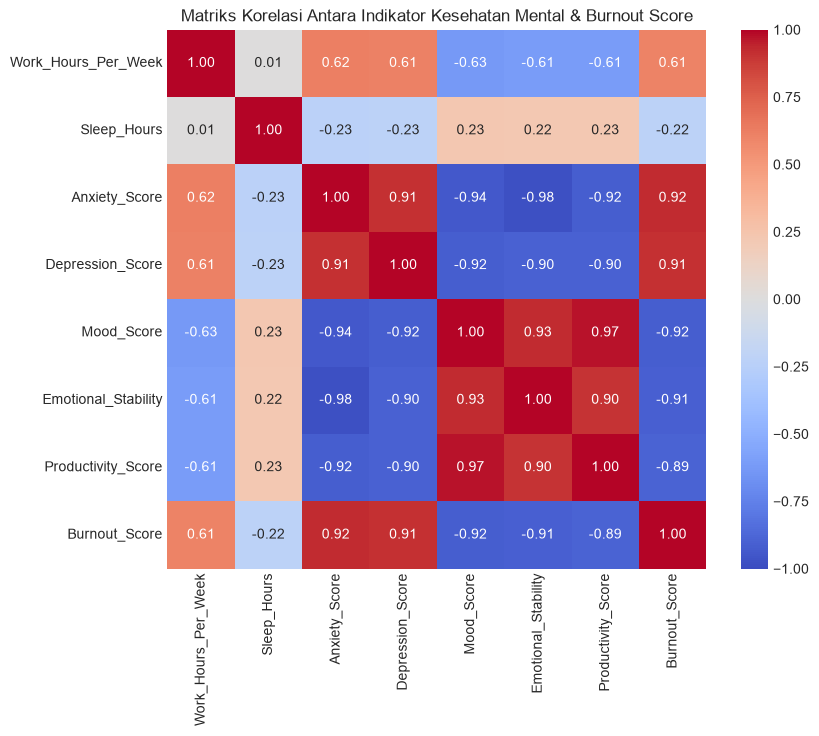

In [8]:
# Heatmap Korelasi Fitur Psikologis dan Beban Kerja terhadap Burnout Score
corr_cols = ['Work_Hours_Per_Week', 'Sleep_Hours', 'Anxiety_Score', 
             'Depression_Score', 'Mood_Score', 'Emotional_Stability', 
             'Productivity_Score', 'Burnout_Score']

plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matriks Korelasi Antara Indikator Kesehatan Mental & Burnout Score', fontsize=12)
plt.show()

### Kesimpulan Analisis JS01:
1. **Karakteristik Data:** Dataset berukuran 50.000 sampel dengan 40 fitur, menyediakan representasi komprehensif profil pekerja modern.
2. **Pola Korelasi:** Korelasi positif yang kuat terlihat antara `Depression_Score` dan `Anxiety_Score` dengan `Burnout_Score`, sedangkan `Sleep_Hours` dan `Mood_Score` berkorelasi negatif terhadap risiko burnout.
3. **Tindak Lanjut Pra-Pengolahan:** Ditemukan *missing values* pada 16 fitur (~1-3%), yang akan ditangani secara terstruktur melalui imputasi pada modul **JS02**.